# newest version config

In [ ]:
import torch, transformers, datasets, platform

print("Torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.9.0+cu128
CUDA: 12.8
Transformers: 5.0.0
Datasets: 4.0.0
Python: 3.12.12
GPU: NVIDIA A100-SXM4-80GB


# older version config

In [ ]:
import torch, transformers, datasets, platform

print("Torch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))


Torch: 2.9.0+cu126
CUDA: 12.6
Transformers: 4.57.6
Datasets: 4.0.0
Python: 3.12.12
GPU: NVIDIA A100-SXM4-80GB


# using latest colab version lets test with transformer older version

In [ ]:
!pip install transformers==4.57.6


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 108.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 54.7 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.4.1
    Uninstalling huggingface_hub-1.4.1:
      Successfully uninstalled huggingface_hub-1.4.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transformers-5.0.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!cp -r /content/drive/MyDrive/deep-past-initiative-machine-translation.zip  /content/deep-past-initiative-machine-translation.zip

In [ ]:
!unzip /content/deep-past-initiative-machine-translation.zip

Archive:  /content/deep-past-initiative-machine-translation.zip
  inflating: OA_Lexicon_eBL.csv      
  inflating: Sentences_Oare_FirstWord_LinNum.csv  
  inflating: bibliography.csv        
  inflating: eBL_Dictionary.csv      
  inflating: publications.csv        
  inflating: published_texts.csv     
  inflating: resources.csv           
  inflating: sample_submission.csv   
  inflating: test.csv                
  inflating: train.csv               


In [ ]:
!cp -r /content/drive/MyDrive/archive.zip  /content/archive.zip

In [ ]:
!unzip /content/archive.zip

Archive:  /content/archive.zip
  inflating: google_madlad400_3b_mt_finetuned_corrected/config.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/generation_config.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00001-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00002-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model-00003-of-00003.safetensors  
  inflating: google_madlad400_3b_mt_finetuned_corrected/model.safetensors.index.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/rng_state.pth  
  inflating: google_madlad400_3b_mt_finetuned_corrected/scheduler.pt  
  inflating: google_madlad400_3b_mt_finetuned_corrected/special_tokens_map.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/spiece.model  
  inflating: google_madlad400_3b_mt_finetuned_corrected/tokenizer.json  
  inflating: google_madlad400_3b_mt_finetuned_corrected/tokenizer_config.json  
  inflati

In [ ]:
import pandas as pd

tr = pd.read_csv('/content/train.csv')
tr['text_combined'] = tr['translation']+''+tr['transliteration']
print(tr['translation'].dropna().str.len().max())
print(tr['transliteration'].dropna().str.len().max())
print(tr['text_combined'].dropna().str.len().max())


3895
932
4787


In [ ]:
df = tr[
    (tr['transliteration'].str.len() <= 640) &
    (tr['translation'].str.len() <= 768)
]

print(df.shape)

(1169, 4)


In [ ]:
tr.shape

(1561, 4)

In [ ]:
tr.columns

Index(['oare_id', 'transliteration', 'translation'], dtype='object')

In [ ]:
translation_max  = tr.loc[tr['translation'].str.len().idxmax(), 'translation']
transliteration_max  = tr.loc[tr['transliteration'].str.len().idxmax(), 'transliteration']

print(translation_max)
print(transliteration_max)

As to the 4 minas of silver that Enna-Suen owed to our father, 2.5 minas of silver, interest, 0.5 mina, expenses on the 5 minas of silver, I received from Enna-Suen. 1 mina of silver furthermore that Ennam-Adad owed I received at the same time from Enna-Suen. When I wrote to Warad-ilī in Kuburnat and ... When I wrote to Katila(?) to Amur-... and ... 4 shekels of silver ... x mina silver ... Šad-ahšu ... 1 mina 5 shekels of silver owed by ...; 0.3333 mina of silver owed by ... x mina of silver ... I received  from the man of Tumliya; 1 mina of silver owed by Ušhata's son; 2.5 mina of silver owed by Ikūn-pīya son of ...; 1 talent of -copper owed by Shorty"; also Shorty gave me a slave-girl and left her with Ah-šalim. I have not yet received Šimašitiša. In all: 30 minas 3 shekels of silver apart from the copper I received from the oustanding claims of my father. 6 minas 15 shekels ... the previous ... 0.5 ... I paid to the office of the colony; 1.5 mina of refined silver under my seal, 10

Loading datasets...

Train dataset shape: (1561, 3)
Test dataset shape: (4, 5)

Train columns: ['oare_id', 'transliteration', 'translation']

Sample training data:
                                oare_id  \
0  004a7dbd-57ce-46f8-9691-409be61c676e   
1  0064939c-59b9-4448-a63d-34612af0a1b5   
2  0073f2c0-524c-4bbf-915a-8c1772a4fb98   

                                     transliteration  \
0  KIŠIB ma-nu-ba-lúm-a-šur DUMU ṣí-lá-(d)IM KIŠI...   
1               1 TÚG ša qá-tim i-tur₄-DINGIR il₅-qé   
2  TÚG u-la i-dí-na-ku-um i-tù-ra-ma 9 GÍN KÙ.BABBAR   

                                         translation  
0  Seal of Mannum-balum-Aššur son of Ṣilli-Adad, ...  
1  Itūr-ilī has received one textile of ordinary ...  
2  ... he did not give you a textile. He returned...  

Loading MADLAD400 tokenizer...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   265.07
  Median: 228.00
  Std:    165.97
  Min:    17
  Max:    635
  75th percentile: 393
  90th percentile: 540
  95th percentile: 553
  99th percentile: 580

📊 TARGET (Translation) Token Lengths:
  Mean:   157.85
  Median: 123.00
  Std:    144.43
  Min:    4
  Max:    1267
  75th percentile: 211
  90th percentile: 317
  95th percentile: 415
  99th percentile: 717

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 553
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 717
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 540
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile

/tmp/ipython-input-1631029989.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


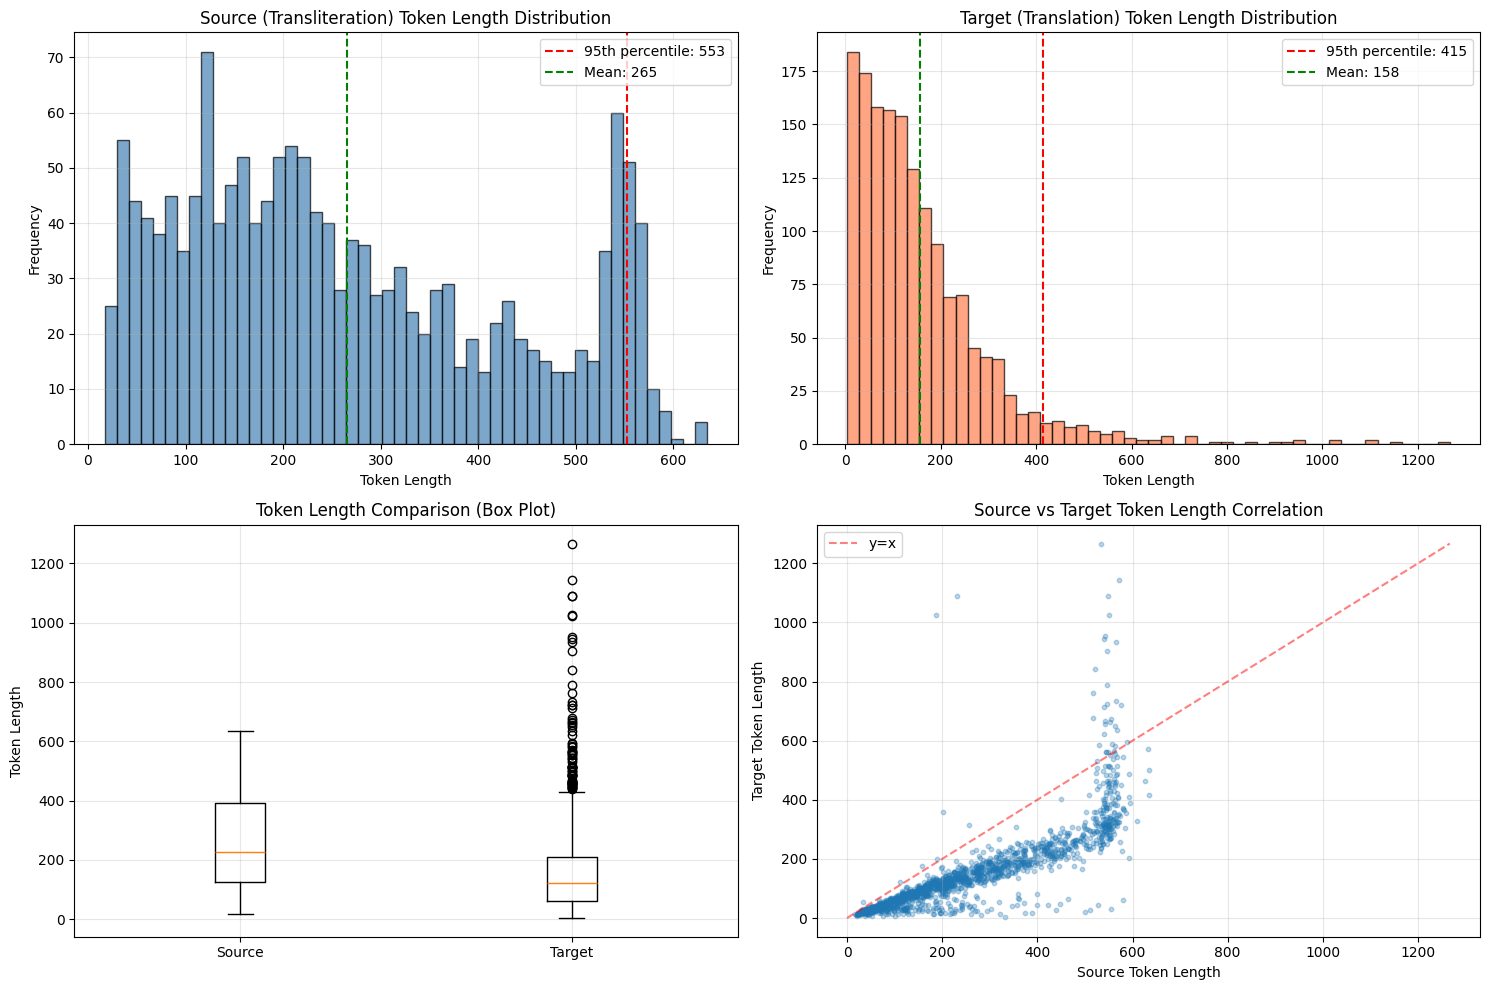


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 553 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ⚠️  Consider adjusting based on your data

3. Samples that will be truncated at 512 tokens:
   - Source: 222 samples (14.22%)
   - Target: 44 samples (2.82%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.2 MB/s eta 0:00:00


In [ ]:
!pip install sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 13.1 MB/s eta 0:00:00


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
from sentence_transformers import SentenceTransformer, util
import evaluate

class Config:
    MODEL_NAME = "google/madlad400-3b-mt"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 3
    LEARNING_RATE = 1e-4
    OUTPUT_DIR = "./madlad400-3b-akkadian"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")
test_df = pd.read_csv(f"{INPUT_DIR}/test.csv")


def simple_sentence_aligner(df):
    aligned_data = []

    for idx, row in df.iterrows():
        src = str(row['transliteration'])
        tgt = str(row['translation'])

        tgt_sents = [t.strip() for t in re.split(r'(?<=[.!?])\s+', tgt) if t.strip()]
        src_lines = [s.strip() for s in src.split('\n') if s.strip()]

        if len(tgt_sents) > 1 and len(tgt_sents) == len(src_lines):
            for s, t in zip(src_lines, tgt_sents):
                if len(s) > 3 and len(t) > 3:
                    aligned_data.append({'transliteration': s, 'translation': t})
        else:
            aligned_data.append({'transliteration': src, 'translation': tgt})

    return pd.DataFrame(aligned_data)


train_expanded = simple_sentence_aligner(train_df)
print(f"Expanded Train Data: {len(train_expanded)} sentences (Alignment applied)")

dataset = Dataset.from_pandas(train_expanded)
split_datasets = dataset.train_test_split(test_size=0.1, seed=42)


# ==========================================
# Tokenization & preprocessing
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = split_datasets["train"].map(preprocess_function, batched=True)
tokenized_val = split_datasets["test"].map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    # FIX 1: Clip predictions to valid token range
    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)

    # FIX 2: Replace invalid tokens with pad token
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        # Fallback: decode one by one and skip problematic sequences
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")  # Empty string for failed decoding

    # Process labels
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",  # Changed to save checkpoints
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=True,

    # FIX 3: Add generation config to prevent overflow
    generation_max_length=Config.MAX_LENGTH,
    generation_num_beams=4,

    logging_steps=10,
    report_to="none",

    greater_is_better=True,
    load_best_model_at_end=True,
    metric_for_best_model="chrf",

    lr_scheduler_type="cosine",
    warmup_steps=100,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=data_collator,
    processing_class=tokenizer,  # FIX 4: Use processing_class instead of tokenizer
    compute_metrics=compute_metrics
)

print("Starting Training with MADLAD400-3B-MT (FP32 mode)...")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")

Expanded Train Data: 1561 sentences (Alignment applied)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

... (8 outputs left out)

Starting Training with MADLAD400-3B-MT (FP32 mode)...


Epoch,Training Loss,Validation Loss,Chrf
1,1.319700,1.297073,34.797976
2,0.892500,1.037243,48.393850
3,0.718000,1.013998,48.321484


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Model saved to ./madlad400-3b-akkadian


In [ ]:
!cp -r /content/madlad400-3b-akkadian/checkpoint-702/  /content/checkpoint-702/

In [ ]:
!rm /content/checkpoint-702/optimizer.pt

# this gave me 30.04 score

# retrain the model with different processing

In [ ]:
!pip install -U kagglehub


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.3/69.3 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.4/160.4 kB 19.1 MB/s eta 0:00:00
  Attempting uninstall: kagglehub
    Found existing installation: kagglehub 0.3.13
    Uninstalling kagglehub-0.3.13:
      Successfully uninstalled kagglehub-0.3.13


In [ ]:
import kagglehub
print(kagglehub.__version__)


0.4.2


In [ ]:
import kagglehub
import os

# ⚠️ Better practice: use secrets, but keeping your example intact
os.environ["KAGGLE_USERNAME"] = "ravikshdikola"
os.environ["KAGGLE_KEY"] = "apply_token_here"

# 👇 Force kagglehub cache to Colab filesystem
#os.environ["KAGGLEHUB_CACHE_DIR"] = "/content/kagglehub"

# # Download dataset
path = kagglehub.dataset_download("ravikshdikola/dpc2-exp2")

print("Dataset downloaded to:", path)


100%|██████████| 10.2G/10.2G [08:00<00:00, 22.7MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1


In [ ]:
import kagglehub
import os

# ⚠️ Better practice: use secrets, but keeping your example intact
os.environ["KAGGLE_USERNAME"] = "ravikshdikola"
os.environ["KAGGLE_KEY"] = "apply_token_here"

# 👇 Force kagglehub cache to Colab filesystem
#os.environ["KAGGLEHUB_CACHE_DIR"] = "/content/kagglehub"

# # Download dataset
path = kagglehub.dataset_download("ravikshdikola/madlab-akkadian-retrained-1st-stage-ciphermix-2ep")

print("Dataset downloaded to:", path)


100%|██████████| 10.2G/10.2G [08:06<00:00, 22.4MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/ravikshdikola/madlab-akkadian-retrained-1st-stage-ciphermix-2ep/versions/1


In [ ]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("ravikshdikola/madlab-akkadian-retrained-1st-stage-ciphermix")

# print("Path to dataset files:", path)

100%|██████████| 10.2G/10.2G [04:46<00:00, 38.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ravikshdikola/madlab-akkadian-retrained-1st-stage-ciphermix/versions/1


In [ ]:
!cp -r /root/.cache/kagglehub/datasets/ravikshdikola/madlab-akkadian-retrained-1st-stage-ciphermix-2ep/versions/1  /content/madlab-ak/

In [ ]:
!cp -r /root/.cache/kagglehub/datasets/ravikshdikola/dpc2-exp2/versions/1   /content/madlab-ak/

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576
    BATCH_SIZE = 1
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


# args = Seq2SeqTrainingArguments(
#     output_dir=Config.OUTPUT_DIR,
#     eval_strategy="no",
#     save_strategy="epoch",
#     learning_rate=Config.LEARNING_RATE,

#     fp16=False,
#     per_device_train_batch_size=1,
#     per_device_eval_batch_size=1,
#     gradient_accumulation_steps=4,

#     weight_decay=0.01,
#     save_total_limit=2,
#     num_train_epochs=Config.EPOCHS,
#     predict_with_generate=False,

#     generation_max_length=Config.MAX_LENGTH,
#     generation_num_beams=4,

#     logging_steps=10,
#     report_to="none",

#     greater_is_better=True,
#     load_best_model_at_end=True,
#     metric_for_best_model="chrf",

#     lr_scheduler_type="cosine",
#     warmup_steps=50,  # Reduced warmup for 1 epoch
#     max_grad_norm=1.0,
# )

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    fp16=False,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=4,

    weight_decay=0.01,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,
    logging_steps=10,
    report_to="none",
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("Starting Training with pretrained MADLAD400-3B-MT...")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"Max Length: {Config.MAX_LENGTH}")
trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"Model saved to {Config.OUTPUT_DIR}")



Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting Training with pretrained MADLAD400-3B-MT...
Learning Rate: 5e-05
Epochs: 1
Max Length: 576


Step,Training Loss
10,0.950200
20,0.992700
30,0.834800
40,0.846800
50,0.873400
60,0.820900
70,0.758700
80,0.856600
90,0.781800
100,0.897800


Model saved to ./madlad400-3b-akkadian-final


# this actuall improve my score to 31.50

# now again experiment with different max_length=732

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 732  # Updated from 576
    BATCH_SIZE = 1  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 8  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 732
Batch Size: 1
Gradient Accumulation Steps: 8
Effective Batch Size: 8
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,1.003700
20,0.907200
30,0.912800
40,0.819700
50,0.840500
60,0.751900
70,0.813700
80,0.672800
90,0.766300
100,0.871300



✓ Model saved to ./madlad400-3b-akkadian-final


# this improve my score to 31.80

# now i am testing it 1080

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 1080  # Updated to 1080
    BATCH_SIZE = 1  # Keep at 1 for FP32 with longer sequences
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings for 1080 tokens with FP32
    GRADIENT_ACCUMULATION_STEPS = 16  # Increased to maintain effective batch size
    USE_GRADIENT_CHECKPOINTING = True  # Essential for longer sequences
    FP16 = False  # Using FP32 for full precision

    # Additional memory optimizations
    DATALOADER_NUM_WORKERS = 0  # Reduce to 0 to save memory with longer sequences
    DATALOADER_PIN_MEMORY = False  # Disable to save memory


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
# Aggressive memory cleanup before loading model
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    torch.cuda.reset_peak_memory_stats()

print("Loading model in FP32...")
model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32,  # FP32 for full precision
    low_cpu_mem_usage=True  # Enable memory-efficient loading
)

# Enable gradient checkpointing - CRITICAL for 1080 sequence length
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

# Additional memory optimization: reduce cache size if model supports it
if hasattr(model.config, 'use_cache'):
    model.config.use_cache = False
    print("✓ Model cache disabled during training")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="epoch",
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings for 1080 sequence length
    fp16=Config.FP16,  # False - using FP32
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management optimized for longer sequences
    dataloader_pin_memory=Config.DATALOADER_PIN_MEMORY,
    dataloader_num_workers=Config.DATALOADER_NUM_WORKERS,

    # Disable some features to save memory
    load_best_model_at_end=False,
    metric_for_best_model=None,

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH,

    # Additional memory optimizations
    ddp_find_unused_parameters=False,
    save_safetensors=True,  # Use safetensors for more efficient saving
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16} (Using FP32)")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print(f"Memory Optimizations: Enabled")
print("=" * 60)

# Monitor memory before training
if torch.cuda.is_available():
    print(f"GPU Memory before training: {torch.cuda.memory_allocated() / 1024**3:.2f} GB allocated")
    print(f"GPU Memory reserved: {torch.cuda.memory_reserved() / 1024**3:.2f} GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

# Final memory stats
if torch.cuda.is_available():
    print(f"\nFinal GPU Memory: {torch.cuda.memory_allocated() / 1024**3:.2f} GB allocated")
    print(f"Peak GPU Memory: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

Total Training Data: 1561 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/1561 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading model in FP32...


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (3 outputs left out)

The model is already on multiple devices. Skipping the move to device specified in `args`.


Starting Training with pretrained MADLAD400-3B-MT
Max Length: 1080
Batch Size: 1
Gradient Accumulation Steps: 16
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False (Using FP32)
Gradient Checkpointing: True
Available VRAM: 80GB
Memory Optimizations: Enabled
GPU Memory before training: 10.95 GB allocated
GPU Memory reserved: 10.96 GB


Step,Training Loss
10,0.980600
20,0.919700
30,0.833600
40,0.781100
50,0.835300
60,0.834400
70,0.768200
80,0.840000
90,0.818300



✓ Model saved to ./madlad400-3b-akkadian-final

Final GPU Memory: 32.88 GB allocated
Peak GPU Memory: 54.82 GB


# this degrade score to 31.20

In [ ]:
# !rm -r /content/madlad400-3b-akkadian-final

rm: cannot remove '/content/madlad400-3b-akkadian-final': No such file or directory


In [ ]:
!rm -r /content/kaggle.json

rm: cannot remove '/content/kaggle.json': No such file or directory


In [ ]:
%%writefile kaggle.json
{
"username":"ravikshdikola","key":"apply token here"
}


Writing kaggle.json


In [ ]:
!rm -rf /content/madlad400-3b-akkadian-final/checkpoint-6558/optimizer.pt

In [ ]:
!mkdir -p ~/.kaggle
!mv kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
%cd /content/madlad400-3b-akkadian-final/checkpoint-6558/


/content/madlad400-3b-akkadian-final/checkpoint-6558


In [ ]:
%%writefile dataset-metadata.json
{
  "title": "madlab Akkadian retrained_2nd_stage_cypuch",
  "id": "ravikshdikola/madlab-akkadian-retrained-2nd-stage-cypuch",
  "licenses": [
    {
      "name": "CC0-1.0"
    }
  ]
}


Writing dataset-metadata.json


In [ ]:
!kaggle datasets create -p .

Starting upload for file model-00002-of-00003.safetensors
100% 4.66G/4.66G [03:26<00:00, 24.2MB/s]
Upload successful: model-00002-of-00003.safetensors (5GB)
Starting upload for file config.json
100% 799/799 [00:00<00:00, 1.04kB/s]
Upload successful: config.json (799B)
Starting upload for file rng_state.pth
100% 14.3k/14.3k [00:00<00:00, 18.6kB/s]
Upload successful: rng_state.pth (14KB)
Starting upload for file tokenizer_config.json
100% 996/996 [00:00<00:00, 1.27kB/s]
Upload successful: tokenizer_config.json (996B)
Skipping folder: .ipynb_checkpoints; use '--dir-mode' to upload folders
Starting upload for file model-00001-of-00003.safetensors
100% 4.63G/4.63G [03:27<00:00, 24.0MB/s]
Upload successful: model-00001-of-00003.safetensors (5GB)
Starting upload for file training_args.bin
100% 5.83k/5.83k [00:00<00:00, 7.51kB/s]
Upload successful: training_args.bin (6KB)
Starting upload for file generation_config.json
100% 122/122 [00:00<00:00, 165B/s]
Upload successful: generation_config.jso

#lets add new dataset and tried to analyze it and do finetuning

In [ ]:
import pandas as pd
from datasets import load_dataset

# Load the dataset
ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)

train = pd.read_csv('/content/train.csv')
train = train.drop(['oare_id'],axis=1)

final_train = pd.concat([df,train])
# frac=1 means "return 100% of the data"
# random_state=42 ensures you get the same shuffle every time you run it
final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
final_train.to_csv('/content/final_train.csv',index=False)



In [ ]:
final_train

,translation,transliteration
0,in the possession of the priest,ŠU.2 ša {LU₂~v}-SANGA
1,"They are waiting for their ... s, their houses...",ina IGI ... ni-šu₂-nu E₂-MEŠ-šu₂-nu ... šu₂-nu...
2,which in their hands,ša₂ ina ŠU.2-šu₂-nu
3,"To the king, my lord: your servant Qurdi-Aššur...",a-na LUGAL be-li₂-ia ARAD-ka {1}-qur-di—aš-šur...
4,that they should bring me,liš-pur {KUR}-un-
...,...,...
57716,Witness,IGI {1}-
57717,The king of Elam has set out. He has sent his ...,šu-tu UD ... KAM₂ is-su-hur ma-a LUGAL {KUR}-N...
57718,"At the command of the gods Aššur, Nabû, (and) ...",... u₂-šak-bi-is-ma ša₂-a-šu₂ ga-du {LU₂}-mun-...
57719,Witness Aššur-na'id.,IGI {1}-aš-šur—I


Loading datasets...

Train dataset shape: (57721, 2)
Test dataset shape: (4, 5)

Train columns: ['translation', 'transliteration']

Sample training data:
                                         translation  \
0                    in the possession of the priest   
1  They are waiting for their ... s, their houses...   
2                              which in their hands    

                                     transliteration  
0                             ŠU.2 ša {LU₂~v}-SANGA   
1  ina IGI ... ni-šu₂-nu E₂-MEŠ-šu₂-nu ... šu₂-nu...  
2                               ša₂ ina ŠU.2-šu₂-nu   

Loading MADLAD400 tokenizer...


config.json:   0%|          | 0.00/749 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/830 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.43M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/16.6M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]


Tokenizing data to analyze length distribution...

TOKEN LENGTH STATISTICS

📊 SOURCE (Transliteration) Token Lengths:
  Mean:   56.24
  Median: 26.00
  Std:    80.46
  Min:    4
  Max:    1743
  75th percentile: 62
  90th percentile: 136
  95th percentile: 209
  99th percentile: 426

📊 TARGET (Translation) Token Lengths:
  Mean:   30.49
  Median: 14.00
  Std:    49.52
  Min:    2
  Max:    1267
  75th percentile: 33
  90th percentile: 71
  95th percentile: 113
  99th percentile: 238

RECOMMENDED MAX_LENGTH SETTINGS

✅ Recommended MAX_LENGTH (covers 95% of data): 209
   - This will truncate ~5% of samples
   - Good balance between coverage and efficiency

⚠️  Conservative MAX_LENGTH (covers 99% of data): 425
   - This will truncate only ~1% of samples
   - Uses more memory but better coverage

🔥 Aggressive MAX_LENGTH (covers 90% of data): 136
   - Fastest training, lowest memory
   - May truncate important content

OUTLIER ANALYSIS

Samples with source length > 95th percentile (209 tok

/tmp/ipython-input-218279686.py:153: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])



✅ Visualization saved as 'token_length_distribution.png'


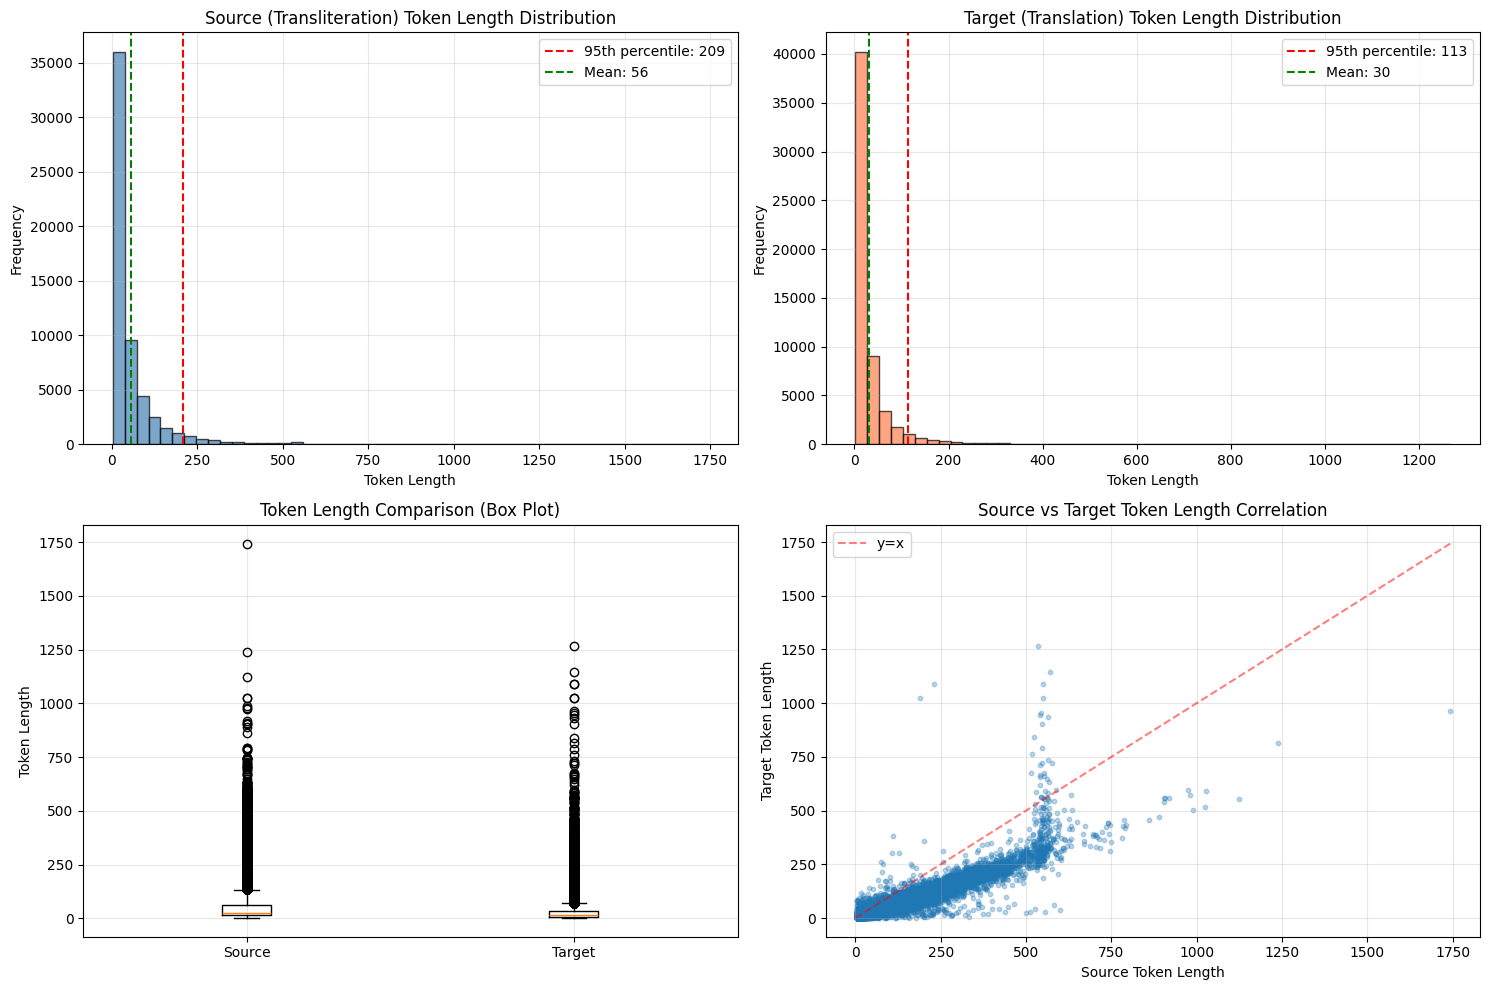


SUMMARY & RECOMMENDATIONS

Based on the analysis:

1. Use MAX_LENGTH = 209 in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - ✅ This is sufficient!

3. Samples that will be truncated at 512 tokens:
   - Source: 331 samples (0.57%)
   - Target: 55 samples (0.10%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoTokenizer

# ==================== CONFIGURATION ====================
BASE_MODEL_NAME = "google/madlad400-3b-mt"
INPUT_DIR = "/content/"
TRAIN_CSV = f"{INPUT_DIR}/final_train.csv"
TEST_CSV = f"{INPUT_DIR}/test.csv"

# ==================== 1. LOAD DATA ====================
print("Loading datasets...")
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)

print(f"\nTrain dataset shape: {train.shape}")
print(f"Test dataset shape: {test.shape}")
print(f"\nTrain columns: {train.columns.tolist()}")

# Display sample data
print("\n" + "="*50)
print("Sample training data:")
print("="*50)
print(train.head(3))

# ==================== 2. LOAD TOKENIZER ====================
print("\n" + "="*50)
print("Loading MADLAD400 tokenizer...")
print("="*50)
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)

# MADLAD400 uses language code prefix (e.g., "<2en>" for English target)
PREFIX = "<2en> "

# ==================== 3. TOKENIZE AND CHECK LENGTHS ====================
print("\nTokenizing data to analyze length distribution...")

# Tokenize source (transliteration) with prefix
source_lengths = train['transliteration'].apply(
    lambda x: len(tokenizer.encode(PREFIX + str(x), add_special_tokens=True))
)

# Tokenize target (translation)
target_lengths = train['translation'].apply(
    lambda x: len(tokenizer.encode(str(x), add_special_tokens=True))
)

# ==================== 4. STATISTICS ====================
print("\n" + "="*50)
print("TOKEN LENGTH STATISTICS")
print("="*50)

print("\n📊 SOURCE (Transliteration) Token Lengths:")
print(f"  Mean:   {source_lengths.mean():.2f}")
print(f"  Median: {source_lengths.median():.2f}")
print(f"  Std:    {source_lengths.std():.2f}")
print(f"  Min:    {source_lengths.min()}")
print(f"  Max:    {source_lengths.max()}")
print(f"  75th percentile: {source_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {source_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {source_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {source_lengths.quantile(0.99):.0f}")

print("\n📊 TARGET (Translation) Token Lengths:")
print(f"  Mean:   {target_lengths.mean():.2f}")
print(f"  Median: {target_lengths.median():.2f}")
print(f"  Std:    {target_lengths.std():.2f}")
print(f"  Min:    {target_lengths.min()}")
print(f"  Max:    {target_lengths.max()}")
print(f"  75th percentile: {target_lengths.quantile(0.75):.0f}")
print(f"  90th percentile: {target_lengths.quantile(0.90):.0f}")
print(f"  95th percentile: {target_lengths.quantile(0.95):.0f}")
print(f"  99th percentile: {target_lengths.quantile(0.99):.0f}")

# ==================== 5. RECOMMENDED MAX_LENGTH ====================
print("\n" + "="*50)
print("RECOMMENDED MAX_LENGTH SETTINGS")
print("="*50)

# Calculate suggested max_length based on percentiles
source_95 = int(source_lengths.quantile(0.95))
target_95 = int(target_lengths.quantile(0.95))
source_99 = int(source_lengths.quantile(0.99))
target_99 = int(target_lengths.quantile(0.99))

suggested_max_length = max(source_95, target_95)
conservative_max_length = max(source_99, target_99)

print(f"\n✅ Recommended MAX_LENGTH (covers 95% of data): {suggested_max_length}")
print(f"   - This will truncate ~5% of samples")
print(f"   - Good balance between coverage and efficiency")

print(f"\n⚠️  Conservative MAX_LENGTH (covers 99% of data): {conservative_max_length}")
print(f"   - This will truncate only ~1% of samples")
print(f"   - Uses more memory but better coverage")

print(f"\n🔥 Aggressive MAX_LENGTH (covers 90% of data): {max(int(source_lengths.quantile(0.90)), int(target_lengths.quantile(0.90)))}")
print(f"   - Fastest training, lowest memory")
print(f"   - May truncate important content")

# ==================== 6. CHECK OUTLIERS ====================
print("\n" + "="*50)
print("OUTLIER ANALYSIS")
print("="*50)

# Find samples with very long sequences
threshold = source_lengths.quantile(0.95)
long_sources = train[source_lengths > threshold]

print(f"\nSamples with source length > 95th percentile ({threshold:.0f} tokens): {len(long_sources)}")
if len(long_sources) > 0:
    print("\nExamples of long transliterations:")
    for idx in long_sources.head(3).index:
        src_len = source_lengths.iloc[idx]
        print(f"\n  Index {idx} (Length: {src_len} tokens):")
        print(f"  {train.loc[idx, 'transliteration'][:200]}...")

# ==================== 7. VISUALIZATIONS ====================
print("\n" + "="*50)
print("GENERATING VISUALIZATIONS")
print("="*50)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Source length distribution
axes[0, 0].hist(source_lengths, bins=50, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(source_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {source_lengths.quantile(0.95):.0f}')
axes[0, 0].axvline(source_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {source_lengths.mean():.0f}')
axes[0, 0].set_xlabel('Token Length')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Source (Transliteration) Token Length Distribution')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Target length distribution
axes[0, 1].hist(target_lengths, bins=50, edgecolor='black', alpha=0.7, color='coral')
axes[0, 1].axvline(target_lengths.quantile(0.95), color='red', linestyle='--',
                   label=f'95th percentile: {target_lengths.quantile(0.95):.0f}')
axes[0, 1].axvline(target_lengths.mean(), color='green', linestyle='--',
                   label=f'Mean: {target_lengths.mean():.0f}')
axes[0, 1].set_xlabel('Token Length')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Target (Translation) Token Length Distribution')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Box plot comparison
data_to_plot = [source_lengths, target_lengths]
axes[1, 0].boxplot(data_to_plot, labels=['Source', 'Target'])
axes[1, 0].set_ylabel('Token Length')
axes[1, 0].set_title('Token Length Comparison (Box Plot)')
axes[1, 0].grid(alpha=0.3)

# Scatter plot: source vs target length
axes[1, 1].scatter(source_lengths, target_lengths, alpha=0.3, s=10)
axes[1, 1].set_xlabel('Source Token Length')
axes[1, 1].set_ylabel('Target Token Length')
axes[1, 1].set_title('Source vs Target Token Length Correlation')
axes[1, 1].grid(alpha=0.3)

# Add diagonal reference line
max_val = max(source_lengths.max(), target_lengths.max())
axes[1, 1].plot([0, max_val], [0, max_val], 'r--', alpha=0.5, label='y=x')
axes[1, 1].legend()

plt.tight_layout()
plt.savefig('token_length_distribution.png', dpi=300, bbox_inches='tight')
print("\n✅ Visualization saved as 'token_length_distribution.png'")
plt.show()

# ==================== 8. SUMMARY ====================
print("\n" + "="*50)
print("SUMMARY & RECOMMENDATIONS")
print("="*50)
print(f"""
Based on the analysis:

1. Use MAX_LENGTH = {suggested_max_length} in your Config class
   - This covers 95% of your data
   - Good balance between efficiency and coverage

2. Current setting in your code: MAX_LENGTH = 512
   - {'✅ This is sufficient!' if 512 >= suggested_max_length else '⚠️  Consider adjusting based on your data'}

3. Samples that will be truncated at 512 tokens:
   - Source: {(source_lengths > 512).sum()} samples ({(source_lengths > 512).sum() / len(source_lengths) * 100:.2f}%)
   - Target: {(target_lengths > 512).sum()} samples ({(target_lengths > 512).sum() / len(target_lengths) * 100:.2f}%)

4. Consider using the sentence aligner to break long texts into smaller chunks
   if truncation affects too many samples.
""")

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=200,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=3,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 57721 sentences


The tokenizer you are loading from '/content/dpc2-exp2/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/57721 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (2 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 576
Batch Size: 4
Gradient Accumulation Steps: 4
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.816300
20,3.609200
30,3.361900
40,3.032200
50,2.936600
60,2.854800
70,2.847100
80,2.686000
90,2.676000
100,2.643900



✓ Model saved to ./madlad400-3b-akkadian-final


# score of 34.5

# lets train it for 2 epoch:

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 2
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=200,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=3,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 57721 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/57721 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.816300
20,3.609200
30,3.361900
40,3.032200
50,2.936600
60,2.854800
70,2.847100
80,2.686800
90,2.674000
100,2.650600


Step,Training Loss
10,3.816300
20,3.609200
30,3.361900
40,3.032200
50,2.936600
60,2.854800
70,2.847100
80,2.686800
90,2.674000
100,2.650600



✓ Model saved to ./madlad400-3b-akkadian-final


# score of 35.3

# after error analysis we are trying to improve processing part

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 2
    LEARNING_RATE = 5e-5
    OUTPUT_DIR = "./madlad400-3b-akkadian-improved"

    # Memory optimization
    GRADIENT_ACCUMULATION_STEPS = 4
    USE_GRADIENT_CHECKPOINTING = True
    FP16 = False


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


# ==========================================
# ENHANCED PREPROCESSING
# ==========================================

def enhanced_preprocess_input(text):
    """Enhanced preprocessing with word boundary protection"""
    if pd.isna(text):
        return ""
    text = str(text)

    # STEP 1: Protect hyphenated names before gap normalization
    protected_hyphens = []
    hyphen_pattern = r'\b([A-Z][a-z]+-[A-Z][a-z]+(?:-[A-Z][a-z]+)?)\b'
    hyphen_matches = list(re.finditer(hyphen_pattern, text))

    for i, match in enumerate(hyphen_matches):
        placeholder = f'__HYPHEN_{i}__'
        protected_hyphens.append((placeholder, match.group(0)))
        text = text.replace(match.group(0), placeholder)

    # STEP 2: Gap normalization
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.{6,}', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    # STEP 3: Restore protected hyphens
    for placeholder, original in protected_hyphens:
        text = text.replace(placeholder, original)

    # STEP 4: Normalize whitespace
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()

    return text


def enhanced_postprocess_output(text):
    """Enhanced postprocessing with gap consolidation"""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # STEP 1: Character normalization
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # STEP 2: Gap consolidation
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.{3,}', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # CRITICAL: Prevent excessive gap repetition (36% CHARACTER_OK issue)
    text = re.sub(r'(<gap>\s*){2,}', '<gap>', text)
    text = re.sub(r'(<big_gap>\s*){3,}', '<big_gap>', text)

    # STEP 3: Remove scribal annotations - FIXED REGEX
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)',
        r'\(fem\.\)',
        r'\(plur\.\)',
        r'\(pl\.\)',
        r'\(sing\.\)',
        r'\(singular\)',
        r'\(plural\)',
        r'\(\?\)',
        r'\(!\)',  # FIXED: removed the \.? part
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # STEP 4: Character denoising
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # STEP 5: Word-level fixes
    text = re.sub(r'([A-Z][a-z]+)\s+-\s+([A-Z][a-z]+)', r'\1-\2', text)
    text = re.sub(r'(\d+(?:\.\d+)?)\s*(mina|shekel|talent)', r'\1 \2', text, flags=re.IGNORECASE)

    # STEP 6: Fraction normalization
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.3333+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.6666+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.3333+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.6666+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # STEP 7: Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)
    text = re.sub(r'\s*-$', '', text)

    return text if text else "broken text"


# ==========================================
# DATA LOADING
# ==========================================

INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")

# Apply enhanced preprocessing
train_df["transliteration"] = train_df["transliteration"].apply(enhanced_preprocess_input)
train_df["translation"] = train_df["translation"].apply(enhanced_postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data
dataset = Dataset.from_pandas(train_df)


# ==========================================
# TOKENIZATION
# ==========================================

tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

# Add special tokens
special_tokens = {
    'additional_special_tokens': ['<gap>', '<big_gap>']
}
num_added = tokenizer.add_special_tokens(special_tokens)
print(f"Added {num_added} special tokens")

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# MODEL SETUP
# ==========================================

gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

if num_added > 0:
    model.resize_token_embeddings(len(tokenizer))
    print("✓ Resized token embeddings")

if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)


# ==========================================
# METRICS
# ==========================================

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [enhanced_postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


# ==========================================
# TRAINING ARGUMENTS
# ==========================================

args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=500,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=3,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)


# ==========================================
# TRAINER
# ==========================================

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 80)
print("TRAINING CONFIGURATION - ENHANCED PREPROCESSING")
print("=" * 80)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Training samples: {len(tokenized_dataset)}")
print("=" * 80)
print("KEY IMPROVEMENTS:")
print("✓ Enhanced input preprocessing (protects hyphenated names)")
print("✓ Gap consolidation in postprocessing (fixes <big_gap> spam)")
print("✓ Word boundary preservation (fixes CHARACTER_OK_WORD_POOR)")
print("=" * 80)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 57721 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Added 2 special tokens


Map:   0%|          | 0/57721 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

... (3 outputs left out)

TRAINING CONFIGURATION - ENHANCED PREPROCESSING
Max Length: 576
Batch Size: 4
Gradient Accumulation: 4
Effective Batch: 16
Learning Rate: 5e-05
Epochs: 2
FP16: False
Gradient Checkpointing: True
Training samples: 57721
KEY IMPROVEMENTS:
✓ Enhanced input preprocessing (protects hyphenated names)
✓ Gap consolidation in postprocessing (fixes <big_gap> spam)
✓ Word boundary preservation (fixes CHARACTER_OK_WORD_POOR)


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,4.177400
20,3.929900
30,3.732900
40,3.460200
50,3.308300
60,3.144100
70,3.216000
80,2.972200
90,2.971300
100,3.010100



✓ Model saved to ./madlad400-3b-akkadian-improved


#lets take a mix of multiple dataset

In [ ]:
import pandas as pd
from datasets import load_dataset

tr = pd.read_csv('/content/train.csv')
tr = tr.drop(['oare_id'],axis=1)

ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)

ds1 = load_dataset("phucthaiv02/akkadian_english_sentences_alignment_2")
df1 = pd.DataFrame(ds1['train'])

ds2 = load_dataset("phucthaiv02/akkadian-translation")
df_train_2 = pd.DataFrame(ds2['train'])
df_val_2 = pd.DataFrame(ds2['validation'])
df2 = pd.concat([df_train_2, df_val_2])
df2 = df2.drop(['pdf_name','page'],axis=1)


f_df = pd.concat([df,df1,df2])

final_train = pd.concat([f_df,tr])
final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
final_train.to_csv('/content/final_train.csv',index=False)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

... (6 outputs left out)

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.28M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/768k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/72653 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1561 [00:00<?, ? examples/s]

In [ ]:
final_train.shape

(142612, 2)

In [ ]:
final_train.head()

,translation,transliteration
0,They brought to you 1 talent 30 1/2 minas of f...,1 ½ GÚ ½ ma-na URUDU SIG5 i-na áb-na-tí-a ub-l...
1,The maid might perish!”,am-tum i-ha-li-iq
2,"As soon as you have seen my letter,",ki-ma d u b -[p]f [ta-mu-ru]
3,"x harbakannu horses,",{KUR}-har-ba-ka-nu
4,"Until I come, let my seal stay.",a-di a-lâ-kà-ni ku-nu-ki-a li-ib-st


In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "/content/madlad400-3b-akkadian-final/"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=300,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=1,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 142612 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/142612 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.130000
20,2.886900
30,2.963400
40,2.926100
50,2.777800
60,2.772300
70,2.634900
80,2.371700
90,2.700400
100,2.360800


Step,Training Loss
10,3.130000
20,2.886900
30,2.963400
40,2.926100
50,2.777800
60,2.772300
70,2.634900
80,2.371700
90,2.700400
100,2.360800



✓ Model saved to /content/madlad400-3b-akkadian-final/


# the degradation is 0.1 %

# this gave me accuracy of 34.4 which is slight degradation compared to previuos pipeline

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 2
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "/content/madlad400-3b-akkadian-final/"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=5000,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=1,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 142612 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/142612 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.128600
20,2.873500
30,2.979100
40,2.911900
50,2.771900
60,2.769000
70,2.627400
80,2.364900
90,2.679500
100,2.356900


Step,Training Loss
10,3.128600
20,2.873500
30,2.979100
40,2.911900
50,2.771900
60,2.769000
70,2.627400
80,2.364900
90,2.679500
100,2.356900



✓ Model saved to /content/madlad400-3b-akkadian-final/


# there is no imporvement i got in it it same 34.4 or 34.3 score so it is a huge let down for me

# (1) one more thing dataset is updated so we changed the processing part a bit to work

# 3  now lets test with bilstm akedemia + cypherling + train dataset

In [ ]:
import re
import pandas as pd
from datasets import load_dataset

# ==========================================
# CORE PROCESSING FUNCTIONS
# ==========================================

def preprocess_input(text):
    """Normalize gaps in transliteration text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<gap>', text)
    text = re.sub(r'\.{6,}', '<gap>', text)
    text = re.sub(r'\.{3}', '<gap>', text)
    text = re.sub(r'……', '<gap>', text)
    text = re.sub(r'…', '<gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r'\bx\b', '<gap>', text)

    # Consolidate consecutive gaps
    text = re.sub(r'(<gap>\s*)+', '<gap>', text)

    # Cleanup
    text = re.sub(r'\s+', ' ', text).strip()

    return text


def postprocess_output(text):
    """Normalize translation text."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"
    if not text.strip():
        return "broken text"

    # ḫ/Ḫ → h/H
    text = text.replace('ḫ', 'h').replace('Ḫ', 'H')

    # Subscript normalization
    subscript_map = {
        '₀':'0','₁':'1','₂':'2','₃':'3','₄':'4',
        '₅':'5','₆':'6','₇':'7','₈':'8','₉':'9'
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # Gap variants → <gap>
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.{3,}', '<gap>', text)
    text = re.sub(r'…', '<gap>', text)
    text = re.sub(r'\[\.+\]', '<gap>', text)

    # Consolidate consecutive gaps
    text = re.sub(r'(<gap>\s*)+', '<gap>', text)

    # Protect <gap> before char stripping
    text = text.replace('<gap>', '\x00GAP\x00')

    # Strip only genuine noise chars
    for char in ['⌈', '⌊', '⌋', 'ʾ']:
        text = text.replace(char, '')

    # Restore
    text = text.replace('\x00GAP\x00', '<gap>')

    # Cleanup
    text = re.sub(r'\s+', ' ', text).strip()
    text = re.sub(r'^-\s*', '', text)
    text = re.sub(r'\s*-$', '', text)

    return text if text else "broken text"


# ==========================================
# DATASET 1 - train.csv (already normalized)
# ==========================================
tr = pd.read_csv('/content/train.csv')
tr = tr.drop(['oare_id'], axis=1)

# Still apply functions to ensure consistency
tr['transliteration'] = tr['transliteration'].apply(preprocess_input)
tr['translation'] = tr['translation'].apply(postprocess_output)

print(f"Dataset 1 (tr): {len(tr)} rows")


# ==========================================
# DATASET 2 - cipher-ling/akkadian
# ==========================================
ds = load_dataset("cipher-ling/akkadian")
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'], axis=1)


def normalize_transliteration_ds2(text):
    if pd.isna(text): return ""
    text = str(text)

    # Fraction normalization — slash fractions
    text = re.sub(r'\b1/2\b', '0.5', text)
    text = re.sub(r'\b1/3\b', '0.3333', text)
    text = re.sub(r'\b2/3\b', '0.6666', text)
    text = re.sub(r'\b1/4\b', '0.25', text)
    text = re.sub(r'\b3/4\b', '0.75', text)
    text = re.sub(r'\b1/5\b', '0.2', text)
    text = re.sub(r'\b1/6\b', '0.1666', text)
    text = re.sub(r'\b5/6\b', '0.8333', text)
    text = re.sub(r'\b1/8\b', '0.125', text)
    text = re.sub(r'\b1/10\b', '0.1', text)

    # Apply core function (handles x, ..., gaps)
    text = preprocess_input(text)
    return text

def normalize_translation_ds2(text):
    if pd.isna(text): return ""
    text = str(text)

    # Fraction normalization — slash fractions
    text = re.sub(r'\b1/2\b', '0.5', text)
    text = re.sub(r'\b1/3\b', '0.3333', text)
    text = re.sub(r'\b2/3\b', '0.6666', text)
    text = re.sub(r'\b1/4\b', '0.25', text)
    text = re.sub(r'\b3/4\b', '0.75', text)
    text = re.sub(r'\b1/5\b', '0.2', text)
    text = re.sub(r'\b1/6\b', '0.1666', text)
    text = re.sub(r'\b5/6\b', '0.8333', text)
    text = re.sub(r'\b1/8\b', '0.125', text)
    text = re.sub(r'\b1/10\b', '0.1', text)

    # Apply core function
    text = postprocess_output(text)
    return text

df['transliteration'] = df['transliteration'].apply(normalize_transliteration_ds2)
df['translation'] = df['translation'].apply(normalize_translation_ds2)

print(f"Dataset 2 (df): {len(df)} rows")


# ==========================================
# DATASET 3 - bilstm_akkedian.csv
# ==========================================
df1 = pd.read_csv('/content/bilstm_akkedian.csv')

def normalize_transliteration_df1(text):
    if pd.isna(text): return ""
    text = str(text)

    # Remove newlines
    text = text.replace('\n', ' ').replace('\r', ' ')

    # ... → <gap>
    text = re.sub(r'\.{3,}', '<gap>', text)
    text = re.sub(r'…', '<gap>', text)

    # x → <gap>
    text = re.sub(r'\bx\b', '<gap>', text)

    # Fraction normalization — slash fractions
    text = re.sub(r'\b1/2\b', '0.5', text)
    text = re.sub(r'\b1/3\b', '0.3333', text)
    text = re.sub(r'\b2/3\b', '0.6666', text)
    text = re.sub(r'\b1/4\b', '0.25', text)
    text = re.sub(r'\b3/4\b', '0.75', text)
    text = re.sub(r'\b1/5\b', '0.2', text)
    text = re.sub(r'\b1/6\b', '0.1666', text)
    text = re.sub(r'\b5/6\b', '0.8333', text)
    text = re.sub(r'\b1/8\b', '0.125', text)
    text = re.sub(r'\b1/10\b', '0.1', text)

    # Apply core function
    text = preprocess_input(text)
    return text


def normalize_translation_df1(text):
    if pd.isna(text): return ""
    text = str(text)

    # Remove newlines
    text = text.replace('\n', ' ').replace('\r', ' ')

    # ... → <gap>
    text = re.sub(r'\.{3,}', '<gap>', text)

    # Fraction normalization — slash fractions
    text = re.sub(r'\b1/2\b', '0.5', text)
    text = re.sub(r'\b1/3\b', '0.3333', text)
    text = re.sub(r'\b2/3\b', '0.6666', text)
    text = re.sub(r'\b1/4\b', '0.25', text)
    text = re.sub(r'\b3/4\b', '0.75', text)
    text = re.sub(r'\b1/5\b', '0.2', text)
    text = re.sub(r'\b1/6\b', '0.1666', text)
    text = re.sub(r'\b5/6\b', '0.8333', text)
    text = re.sub(r'\b1/8\b', '0.125', text)
    text = re.sub(r'\b1/10\b', '0.1', text)



    # Remove trailing semicolons
    text = re.sub(r'\s*;\s*$', '', text)

    # Apply core function
    text = postprocess_output(text)
    return text

df1['transliteration'] = df1['transliteration'].apply(normalize_transliteration_df1)
df1['translation'] = df1['translation'].apply(normalize_translation_df1)

print(f"Dataset 3 (df1): {len(df1)} rows")


# ==========================================
# COMBINE & FINALIZE
# ==========================================
final_train = pd.concat([tr, df, df1], ignore_index=True)

# Drop nulls and empty strings
final_train = final_train.dropna(subset=['transliteration', 'translation'])
final_train = final_train[
    (final_train['transliteration'].str.strip() != '') &
    (final_train['translation'].str.strip() != '') &
    (final_train['translation'] != 'broken text')
]

# Shuffle
final_train = final_train.sample(frac=1, random_state=42).reset_index(drop=True)
final_train.to_csv('/content/final_train.csv', index=False)

print(f"\nFinal dataset: {len(final_train)} rows")
print(f"  tr:  {len(tr)}")
print(f"  df:  {len(df)}")
print(f"  df1: {len(df1)}")
print(f"\nSample row:")
print(final_train[['transliteration', 'translation']].iloc[0])

Dataset 1 (tr): 1562 rows


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2870 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2812 [00:00<?, ? examples/s]

Dataset 2 (df): 56160 rows
Dataset 3 (df1): 201231 rows

Final dataset: 258953 rows
  tr:  1562
  df:  56160
  df1: 201231

Sample row:
transliteration    man-nu ša ina ur-kiš ina ma-te-ma de-e-nu DUG₄...
translation        Whoever in the future, at any time, seeks a la...
Name: 0, dtype: object


In [ ]:
final_train.shape

(258953, 2)

In [ ]:
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"
    MAX_LENGTH = 576
    BATCH_SIZE = 4
    EPOCHS = 1
    LEARNING_RATE = 5e-5
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"
    GRADIENT_ACCUMULATION_STEPS = 4
    USE_GRADIENT_CHECKPOINTING = True
    FP16 = False


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


# ==========================================
# LOAD DATA (already preprocessed)
# ==========================================
INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/final_train.csv")

print(f"Total Training Data: {len(train_df)} sentences")

dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model Training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32
)

if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=10000,
    learning_rate=Config.LEARNING_RATE,
    fp16=Config.FP16,
    per_device_train_batch_size=Config.BATCH_SIZE,
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,
    optim="adamw_torch",
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,
    logging_steps=10,
    report_to="none",
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,
    dataloader_pin_memory=True,
    dataloader_num_workers=2,
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length:                {Config.MAX_LENGTH}")
print(f"Batch Size:                {Config.BATCH_SIZE}")
print(f"Gradient Accumulation:     {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size:      {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate:             {Config.LEARNING_RATE}")
print(f"Epochs:                    {Config.EPOCHS}")
print(f"FP16:                      {Config.FP16}")
print(f"Gradient Checkpointing:    {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM:            80GB")
print("=" * 60)

trainer.train()

trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 258953 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/258953 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (3 outputs left out)

`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,4.146200
20,3.779000
30,3.504200
40,3.300900
50,3.182900
60,3.009400
70,3.052400
80,2.878900
90,2.850800
100,2.824500


Step,Training Loss
10,4.146200
20,3.779000
30,3.504200
40,3.300900
50,3.182900
60,3.009400
70,3.052400
80,2.878900
90,2.850800
100,2.824500



✓ Model saved to ./madlad400-3b-akkadian-final


# lets do some seperate preprocessing to build data and then do its training cypher + phucthaiv02 with some data preprocessing

In [ ]:
import pandas as pd
from datasets import load_dataset

ds = load_dataset("cipher-ling/akkadian")
# This takes the list of dictionaries and turns keys into column headers
df_train = pd.DataFrame(ds['train']['translation'])
df_val = pd.DataFrame(ds['validation']['translation'])
df_test = pd.DataFrame(ds['test']['translation'])

df = pd.concat([df_train, df_val, df_test])
df.rename(columns={'en': 'translation', 'tr': 'transliteration'}, inplace=True)
df = df.drop(['ak'],axis=1)
df.to_csv('cipher-ling.csv',index=False)



ds_1 = load_dataset("phucthaiv02/akkadian-translation")
df_train_1 = pd.DataFrame(ds_1['train'])
df_val_1 = pd.DataFrame(ds_1['validation'])
df_1 = pd.concat([df_train_1, df_val_1])
df_1.to_csv('phucthaiv02.csv',index=False)


tr = pd.read_csv('/content/train_old.csv')
print(tr.shape)
print(df.shape)
print(df_1.shape)


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/597 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/6.57M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/429k [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/430k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50478 [00:00<?, ? examples/s]

... (4 outputs left out)

data/validation-00000-of-00001.parquet:   0%|          | 0.00/768k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/72653 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1561 [00:00<?, ? examples/s]

(1561, 3)
(56160, 2)
(74214, 4)


In [ ]:
import pandas as pd

# ─────────────────────────────────────────
# 1. LOAD
# ─────────────────────────────────────────
train_old = pd.read_csv('train_old.csv')[['transliteration', 'translation']]
phuc      = pd.read_csv('phucthaiv02.csv')[['transliteration', 'translation']]
cipher    = pd.read_csv('cipher-ling.csv')[['transliteration', 'translation']]

print(f"Loaded  →  train_old: {len(train_old)}  |  phuc: {len(phuc)}  |  cipher: {len(cipher)}")


# ─────────────────────────────────────────
# 2. HELPER FUNCTIONS
# ─────────────────────────────────────────


def check_encoding(df, name):
    """
    Drop only rows with actual unicode replacement character \ufffd.
    NOTE: '?' is valid assyriological notation for uncertain readings — do NOT filter it.
    '□' can also appear in scholarly transcriptions — do NOT filter it.
    Only \ufffd is a true encoding corruption marker.
    """
    bad = df['transliteration'].str.contains('\ufffd', regex=False)
    print(f"[{name}] Encoding corrupted rows dropped: {bad.sum()}")
    return df[~bad].reset_index(drop=True)

def drop_short_translation(df, min_len, name):
    """Drop rows where translation is shorter than min_len characters."""
    before = len(df)
    mask = df['translation'].str.len() >= min_len
    df = df[mask].reset_index(drop=True)
    print(f"[{name}] Dropped {before - len(df)} rows with translation < {min_len} chars  →  {len(df)} remaining")
    return df

def drop_short_both(df, min_len, name):
    """Drop rows where EITHER transliteration or translation is shorter than min_len."""
    before = len(df)
    mask = (df['transliteration'].str.len() >= min_len) & (df['translation'].str.len() >= min_len)
    df = df[mask].reset_index(drop=True)
    print(f"[{name}] Dropped {before - len(df)} rows with either column < {min_len} chars  →  {len(df)} remaining")
    return df

def drop_bad_ratio(df, min_ratio, max_ratio, name):
    """
    Drop rows where transliteration/translation length ratio is outside range.
    Catches truncated transliterations mapped to long translations and vice versa.
    """
    before = len(df)
    ratio = df['transliteration'].str.len() / df['translation'].str.len()
    mask = (ratio >= min_ratio) & (ratio <= max_ratio)
    df = df[mask].reset_index(drop=True)
    print(f"[{name}] Dropped {before - len(df)} rows with bad length ratio ({min_ratio}-{max_ratio})  →  {len(df)} remaining")
    return df

def drop_unpreserved_translations(df, name):
    """Drop rows where translation explicitly states the tablet is unreadable."""
    before = len(df)
    bad_phrases = [
        'not preserved',
        'too poorly preserved',
        'not sufficiently preserved',
        'poorly preserved',
        'not allow translation'
    ]
    pattern = '|'.join(bad_phrases)
    mask = ~df['translation'].str.lower().str.contains(pattern, regex=True)
    df = df[mask].reset_index(drop=True)
    print(f"[{name}] Dropped {before - len(df)} unpreserved/unreadable tablet rows  →  {len(df)} remaining")
    return df

def drop_low_content_translations(df, name):
    """Drop rows where translation is just punctuation, a single word, or numbers only."""
    before = len(df)
    mask = df['translation'].str.strip().str.contains(r'\b\w+\b.*\b\w+\b', regex=True)
    df = df[mask].reset_index(drop=True)
    print(f"[{name}] Dropped {before - len(df)} single-word/punctuation-only translations  →  {len(df)} remaining")
    return df


# ─────────────────────────────────────────
# 3. CLEAN EACH DATASET
# ─────────────────────────────────────────

# --- train_old ---

train_old = check_encoding(train_old, 'train_old')
print(f"train_old final: {len(train_old)}\n")

# --- phucthaiv02 ---
# '?' is valid assyriological notation — only filter true unicode corruption (\ufffd)

phuc = check_encoding(phuc, 'phucthaiv02')
phuc = drop_short_translation(phuc, min_len=10, name='phucthaiv02')
phuc = drop_bad_ratio(phuc, min_ratio=0.2, max_ratio=5.0, name='phucthaiv02')
print(f"phucthaiv02 final: {len(phuc)}\n")

# --- cipher-ling ---

cipher = check_encoding(cipher, 'cipher-ling')
cipher = drop_short_both(cipher, min_len=10, name='cipher-ling')
cipher = drop_bad_ratio(cipher, min_ratio=0.2, max_ratio=5.0, name='cipher-ling')
cipher = drop_unpreserved_translations(cipher, name='cipher-ling')
cipher = drop_low_content_translations(cipher, name='cipher-ling')
print(f"cipher-ling final: {len(cipher)}\n")


# ─────────────────────────────────────────
# 4. MERGE & DEDUPLICATE
# ─────────────────────────────────────────

merged = pd.concat([train_old, phuc, cipher], ignore_index=True)
print(f"After concat: {len(merged)}")

before = len(merged)
merged = merged.drop_duplicates(subset='transliteration', keep='first').reset_index(drop=True)
print(f"After dedup: dropped {before - len(merged)} duplicates  →  {len(merged)} remaining")


# ─────────────────────────────────────────
# 5. FINAL SANITY CHECK
# ─────────────────────────────────────────

print(f"\n=== FINAL DATASET ===")
print(f"Total rows     : {len(merged)}")
print(f"Nulls          : {merged.isnull().sum().to_dict()}")
print(f"Avg translit   : {merged['transliteration'].str.len().mean():.1f} chars")
print(f"Avg translation: {merged['translation'].str.len().mean():.1f} chars")
print(f"Min translit   : {merged['transliteration'].str.len().min()}")
print(f"Min translation: {merged['translation'].str.len().min()}")

merged = merged.sample(frac=1, random_state=42).reset_index(drop=True)

# ─────────────────────────────────────────
# 6. SAVE
# ─────────────────────────────────────────

merged.to_csv('train_merged_clean.csv', index=False)
print(f"\nSaved → train_merged_clean.csv")

Loaded  →  train_old: 1561  |  phuc: 74214  |  cipher: 56160
[train_old] Encoding corrupted rows dropped: 0
train_old final: 1561

[phucthaiv02] Encoding corrupted rows dropped: 0
[phucthaiv02] Dropped 142 rows with translation < 10 chars  →  74072 remaining
[phucthaiv02] Dropped 79 rows with bad length ratio (0.2-5.0)  →  73993 remaining
phucthaiv02 final: 73993

[cipher-ling] Encoding corrupted rows dropped: 0
[cipher-ling] Dropped 7884 rows with either column < 10 chars  →  48276 remaining
[cipher-ling] Dropped 192 rows with bad length ratio (0.2-5.0)  →  48084 remaining
[cipher-ling] Dropped 16 unpreserved/unreadable tablet rows  →  48068 remaining
[cipher-ling] Dropped 633 single-word/punctuation-only translations  →  47435 remaining
cipher-ling final: 47435

After concat: 122989
After dedup: dropped 18068 duplicates  →  104921 remaining

=== FINAL DATASET ===
Total rows     : 104921
Nulls          : {'transliteration': 0, 'translation': 0}
Avg translit   : 81.6 chars
Avg translat

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()


INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train_merged_clean.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=3500,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=2,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 104921 sentences


The tokenizer you are loading from '/content/madlab-ak/google_madlad400_3b_mt_finetuned_corrected/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/104921 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (2 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 576
Batch Size: 4
Gradient Accumulation Steps: 4
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,3.524500
20,3.370000
30,3.112700
40,2.860800
50,2.860500
60,2.904300
70,2.546500
80,2.619500
90,2.759400
100,2.429100



✓ Model saved to ./madlad400-3b-akkadian-final


# this gave 33.3 on unseen set

In [ ]:
import os
import gc
import re
import pandas as pd
import numpy as np
import torch
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer
)
import evaluate

class Config:
    MODEL_NAME = "/content/madlab-ak/"  # Your pretrained model path
    MAX_LENGTH = 576  # Updated from 576
    BATCH_SIZE = 4  # Reduced for FP32 (double memory vs FP16)
    EPOCHS = 1
    LEARNING_RATE = 5e-5  # Lower learning rate for fine-tuning already trained model
    OUTPUT_DIR = "./madlad400-3b-akkadian-final"

    # Memory optimization settings
    GRADIENT_ACCUMULATION_STEPS = 4  # Increased for FP32 memory constraints
    USE_GRADIENT_CHECKPOINTING = True  # Enable for longer sequences
    FP16 = False  # Using FP32 for full precision


def seed_everything(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed(seed)

seed_everything()

INPUT_DIR = "/content/"
train_df = pd.read_csv(f"{INPUT_DIR}/train_merged_clean.csv")


# ==========================================
# PREPROCESSING (from inference pipeline)
# ==========================================

def preprocess_input(text):
    """Normalize gaps in INPUT text."""
    if pd.isna(text):
        return ""
    text = str(text)

    # Multi-dot patterns → <big_gap>
    text = re.sub(r'\.{3}(?:\s+\.{3})+', '<big_gap>', text)
    text = re.sub(r'\.\.\.\.\.\.', '<big_gap>', text)
    text = re.sub(r'\.\.\.', '<big_gap>', text)
    text = re.sub(r'……', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)

    # x patterns → <gap>
    text = re.sub(r'xx+', '<gap>', text)
    text = re.sub(r' x ', ' <gap> ', text)

    return text


def postprocess_output(text):
    """Post-processing with proven optimizations."""
    if not isinstance(text, str):
        return str(text) if text else "broken text"

    if not text.strip():
        return "broken text"

    # 1. ḫ/Ḫ → h/H conversion
    text = text.replace('ḫ', 'h')
    text = text.replace('Ḫ', 'H')

    # 2. Subscript number normalization
    subscript_map = {
        '₀': '0', '₁': '1', '₂': '2', '₃': '3', '₄': '4',
        '₅': '5', '₆': '6', '₇': '7', '₈': '8', '₉': '9',
    }
    for sub, normal in subscript_map.items():
        text = text.replace(sub, normal)

    # 3. Convert gap patterns in output to proper tags
    text = re.sub(r'\[x\]', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\(x\)', '<gap>', text, flags=re.IGNORECASE)
    text = re.sub(r'\bx\b', '<gap>', text)
    text = re.sub(r'\.\.\.+', '<big_gap>', text)
    text = re.sub(r'…', '<big_gap>', text)
    text = re.sub(r'\[\.+\]', '<big_gap>', text)

    # 4. Gap consolidation
    text = re.sub(r'<gap>\s*<gap>', '<big_gap>', text)
    text = re.sub(r'<big_gap>\s*<big_gap>', '<big_gap>', text)

    # 5. Remove scribal annotations
    scribal_patterns = [
        r'\(fem\.\s*plur\.\)', r'\(fem\.\)', r'\(plur\.\)',
        r'\(pl\.\)', r'\(sing\.\)', r'\(singular\)', r'\(plural\)',
        r'\(\?\)', r'\(!\)',
    ]
    for pattern in scribal_patterns:
        text = re.sub(pattern, '', text, flags=re.IGNORECASE)

    # 6. Character denoising (protect gap tags first)
    text = text.replace('<gap>', '\x00GAP\x00')
    text = text.replace('<big_gap>', '\x00BIGGAP\x00')

    forbidden_chars = [
        '!', '?', '(', ')', '"', '"', '"', ';', '—', '–',
        '<', '>', '⌈', '⌊', '⌋', '[', ']', '+', 'ʾ', '/',
    ]
    for char in forbidden_chars:
        text = text.replace(char, '')

    text = text.replace('\x00GAP\x00', '<gap>')
    text = text.replace('\x00BIGGAP\x00', '<big_gap>')

    # 7. Fraction normalization
    # Decimal fractions
    text = re.sub(r'(\d+)\.5\b', r'\1 ½', text)
    text = re.sub(r'(\d+)\.33+\d*\b', r'\1 ⅓', text)
    text = re.sub(r'(\d+)\.66+\d*\b', r'\1 ⅔', text)
    text = re.sub(r'(\d+)\.25\b', r'\1 ¼', text)
    text = re.sub(r'(\d+)\.75\b', r'\1 ¾', text)

    # Standalone fractions
    text = re.sub(r'\b0\.5\b', '½', text)
    text = re.sub(r'\b0\.33+\d*\b', '⅓', text)
    text = re.sub(r'\b0\.66+\d*\b', '⅔', text)
    text = re.sub(r'\b0\.25\b', '¼', text)
    text = re.sub(r'\b0\.75\b', '¾', text)

    # Space-separated fractions (after / removal)
    text = text.replace(' 1 2', ' ½')
    text = text.replace(' 1 3', ' ⅓')
    text = text.replace(' 2 3', ' ⅔')
    text = text.replace(' 1 4', ' ¼')
    text = text.replace(' 3 4', ' ¾')

    # 8. Final cleanup
    text = re.sub(r'\s+', ' ', text)
    text = text.strip()
    text = re.sub(r'^-\s*', '', text)  # Remove leading dash
    text = re.sub(r'\s*-$', '', text)  # Remove trailing dash

    return text if text else "broken text"


# Apply preprocessing to train data
train_df["transliteration"] = train_df["transliteration"].apply(preprocess_input)
train_df["translation"] = train_df["translation"].apply(postprocess_output)

print(f"Total Training Data: {len(train_df)} sentences")

# Create dataset from entire training data (no split)
dataset = Dataset.from_pandas(train_df)


# ==========================================
# Tokenization
# ==========================================
tokenizer = AutoTokenizer.from_pretrained(Config.MODEL_NAME)

PREFIX = "<2en> "

def preprocess_function(examples):
    inputs = [PREFIX + str(ex) for ex in examples["transliteration"]]
    targets = [str(ex) for ex in examples["translation"]]

    model_inputs = tokenizer(inputs, max_length=Config.MAX_LENGTH, truncation=True)
    labels = tokenizer(targets, max_length=Config.MAX_LENGTH, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_dataset = dataset.map(preprocess_function, batched=True)


# ==========================================
# Model training
# ==========================================
gc.collect()
torch.cuda.empty_cache()

model = AutoModelForSeq2SeqLM.from_pretrained(
    Config.MODEL_NAME,
    device_map='auto',
    torch_dtype=torch.float32  # Using FP32 for full precision
)

# Enable gradient checkpointing for longer sequences
if Config.USE_GRADIENT_CHECKPOINTING:
    model.gradient_checkpointing_enable()
    print("✓ Gradient checkpointing enabled for memory efficiency")

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

metric = evaluate.load("chrf")

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]

    vocab_size = len(tokenizer)
    preds = np.clip(preds, 0, vocab_size - 1)
    preds = np.where((preds >= 0) & (preds < vocab_size), preds, tokenizer.pad_token_id)

    try:
        decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
    except OverflowError:
        decoded_preds = []
        for pred in preds:
            try:
                decoded_preds.append(tokenizer.decode(pred, skip_special_tokens=True))
            except (OverflowError, ValueError):
                decoded_preds.append("")

    # Apply post-processing to predictions
    decoded_preds = [postprocess_output(pred) for pred in decoded_preds]

    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)
    decoded_labels = [[label.strip()] for label in decoded_labels]

    result = metric.compute(predictions=decoded_preds, references=decoded_labels)
    return {"chrf": result["score"]}


args = Seq2SeqTrainingArguments(
    output_dir=Config.OUTPUT_DIR,
    eval_strategy="no",
    save_strategy="steps",
    save_steps=200,
    learning_rate=Config.LEARNING_RATE,

    # Memory optimization settings
    fp16=Config.FP16,  # Enable mixed precision
    per_device_train_batch_size=Config.BATCH_SIZE,  # Increased to 2
    per_device_eval_batch_size=Config.BATCH_SIZE,
    gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS,

    # Optimizer settings
    optim="adamw_torch",  # Explicit optimizer
    weight_decay=0.01,
    adam_beta1=0.9,
    adam_beta2=0.999,
    adam_epsilon=1e-8,

    # Training settings
    save_total_limit=3,
    num_train_epochs=Config.EPOCHS,
    predict_with_generate=False,

    logging_steps=10,
    report_to="none",

    # Learning rate schedule
    lr_scheduler_type="cosine",
    warmup_steps=50,
    max_grad_norm=1.0,

    # Memory management
    dataloader_pin_memory=True,
    dataloader_num_workers=2,  # Parallel data loading

    # Generation settings (for evaluation if needed)
    generation_max_length=Config.MAX_LENGTH
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


print("=" * 60)
print("Starting Training with pretrained MADLAD400-3B-MT")
print("=" * 60)
print(f"Max Length: {Config.MAX_LENGTH}")
print(f"Batch Size: {Config.BATCH_SIZE}")
print(f"Gradient Accumulation Steps: {Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Effective Batch Size: {Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS}")
print(f"Learning Rate: {Config.LEARNING_RATE}")
print(f"Epochs: {Config.EPOCHS}")
print(f"FP16: {Config.FP16}")
print(f"Gradient Checkpointing: {Config.USE_GRADIENT_CHECKPOINTING}")
print(f"Available VRAM: 80GB")
print("=" * 60)

trainer.train()

# Save Model
trainer.save_model(Config.OUTPUT_DIR)
tokenizer.save_pretrained(Config.OUTPUT_DIR)
print(f"\n✓ Model saved to {Config.OUTPUT_DIR}")

Total Training Data: 104921 sentences


The tokenizer you are loading from '/content/madlab-ak/' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Map:   0%|          | 0/104921 [00:00<?, ? examples/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

The module name  (originally ) is not a valid Python identifier. Please rename the original module to avoid import issues.


... (2 outputs left out)

Starting Training with pretrained MADLAD400-3B-MT
Max Length: 576
Batch Size: 4
Gradient Accumulation Steps: 4
Effective Batch Size: 16
Learning Rate: 5e-05
Epochs: 1
FP16: False
Gradient Checkpointing: True
Available VRAM: 80GB


`use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`...


Step,Training Loss
10,2.075500
20,1.738000
30,1.749100
40,1.872900
50,1.677300
60,1.535800
70,1.683800
80,1.600600
90,1.645100
100,1.508200



✓ Model saved to ./madlad400-3b-akkadian-final


# this gave 35.1 no improvement